# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 3. Логистическая регрессия.


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 30 баллов;
* Задача 2 &mdash; 20 баллов;
* Задача 3 &mdash; 20 баллов;
* Задача 4 &mdash; 30 баллов;
* Задача 5 &mdash; 90 баллов.

In [537]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from time import time
from typing import Literal
from sklearn.linear_model import LogisticRegression
from sklearn.base import BaseEstimator

sns.set(style="whitegrid", palette="Set2")

In [538]:
# Bot check

# HW_ID: fpmi_ad3
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1, 2, 3**
1. https://chat.deepseek.com/share/l1kefzwr0wk0mykzt1
    - просила закодить только формулу и задвала вопросы про методы, синтаксис, для чего используется


### 📌 Примечание

В ходе доработки решения были внесены следующие исправления:

**Задача 2:**
- Доработан итоговый **вывод** в конце задания. Исправлено замечание: ▫️ В выводе ничего не сказано про несмещенность оценок вероятностей.

**Задача 3, Пункт 2:**
- Исправлено замечание: ▫️ Ошибка в размерностях матриц.
- В формуле градиента была ошибка размерности. В исходной записи были скалярные величины $\mathbf{1}\{Y_i = k\}$ и $\sigma_k(\theta x_i)$, умноженные на  $x_i$, что давало вектор размера $d$, а не матрицу $K×d$. Исправлено на векторную запись: $\mathbf{1}(Y_i) \in \mathbb{R}^K$ и $\sigma(\theta x_i) \in \mathbb{R}^K$, внешнее произведение на $x_i^\top$. Теперь получается корректная матрица $K×d$.
- Аналогичное исправление в формуле GD и SGD.

**Задача 4:**
- Исправлено: ▫️ Некорректный выбор батча в SGD.
- Теперь в методе fit для SGD используется выбор батчей с повторением (replace=True) на каждой итерации.


*Привет!*

*Перед тобой увлекательная домашка по логистической регрессии и градиентным методам оптимизации. Надеемся, что тебе она понравится, ты точно найдешь в ней что-то интересное. В условии оставлены некоторые скрытые подсказки, будет хорошо, если ты сначала постараешься подумать самостоятельно, а затем раскроешь содержимое подсказки. Если у тебя будут вопросы по условию, можешь обратиться с ними в чат. Только очень желательно не делиться в чате фрагментами решения.*

*Успехов в решении!*

---
### Задача 1.

*Для начала посмотрим на простых примерах, как работает логистическая регрессия, и поймем некоторые ее важные свойства. Перед выполнением задачи ознакомтесь с ноутбуком по логистической регрессии с занятия.*

> Одно из интересных свойств модели логистической регрессии — *при соблюдении её предположений* она дает возможность получать **несмещенные оценки вероятностей** принадлежности объекта к определенному классу. Понимать это можно следующим образом. Рассмотрим объект $x$ и соответствующее предсказание вероятности $\widehat{p}(x)$ для класса 1. Если взять небольшую окрестность объекта $x$, то доля объектов с истинным классом 1 в этой окрестности будет приблизительно равна $\widehat{p}(x)$.  

Далее проверим это свойство на примере.

С помощью кода ниже сгенерируйте данные, состоящие из одного вещественного признака и бинарного таргета.

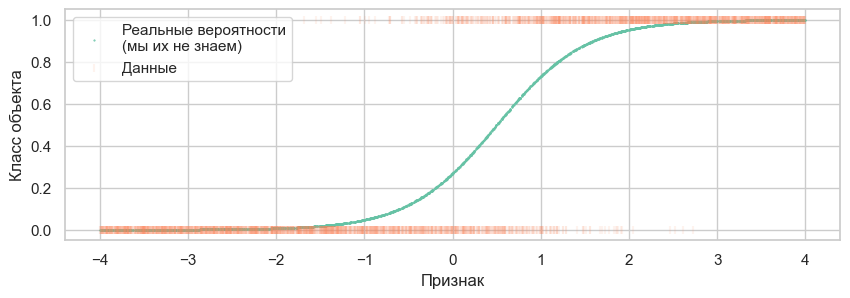

In [539]:
np.random.seed(26)

sample_size = 3000

X_train = np.random.uniform(low=-4, high=4, size=(sample_size, 1))
y_mean_true = 1 / (1 + np.exp(1 - 2 * X_train.ravel()))
y_train = np.random.binomial(n=1, p=y_mean_true)
sample_size = 3_000  # Размер выборки

# Признаки
X_train = np.random.uniform(low=-4, high=4, size=(sample_size, 1))

# Таргет
y_mean_true = 1 / (1 + np.exp(1 - 2 * X_train.ravel()))
y_train = np.random.binomial(n=1, p=y_mean_true)

plt.figure(figsize=(10, 3))
plt.scatter(X_train, y_mean_true, marker=".", s=1, label="Реальные вероятности\n(мы их не знаем)")
plt.scatter(X_train, y_train, marker="|", alpha=0.1, label="Данные")
plt.xlabel("Признак")
plt.ylabel("Класс объекта")
plt.legend();

Обучите логистическую регрессию, используя реализацию из `sklearn`, при этом свободный коэффициент должен присутствовать в модели. Укажите также `penalty='none'`.

*Делить данные на обучающую и тестовую части в данном случае не нужно, поскольку цель данной задачи &mdash; посмотреть, как модель представляет исходные данные, а не оценить ее качество.*

In [540]:
model = LogisticRegression(
    penalty=None,
    fit_intercept=True,
    solver="lbfgs",
    max_iter=1000
)

model.fit(X_train, y_train)

/Users/dianakurnicova/Documents/vvad_hw1/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass`

Напечатайте оценку коэффициентов из обученной модели

In [541]:
print("Свободный коэффициент:", model.intercept_[0])
print("Коэффициент при признаке:", model.coef_[0][0])

Свободный коэффициент: -1.0099868433073849
Коэффициент при признаке: 2.0784235976673244


Вспомним, обученная модель представляет собой функцию $\widehat{p}: \mathbb{R} \to [0, 1]$, которая для каждого объекта $x \in \mathbb{R}$ возвращает для него оценку вероятности класса 1. Постройте график этой функции.

Ниже объявлена сетка значений  $x \in \mathbb{R}$ для построения графика. На этом же графике:
* постройте предсказания вероятностей класса 1 (бинаризация оценок вероятностей),
* отобразите обучающую выборку.

Похожий график есть в ноутбуке с занятия.

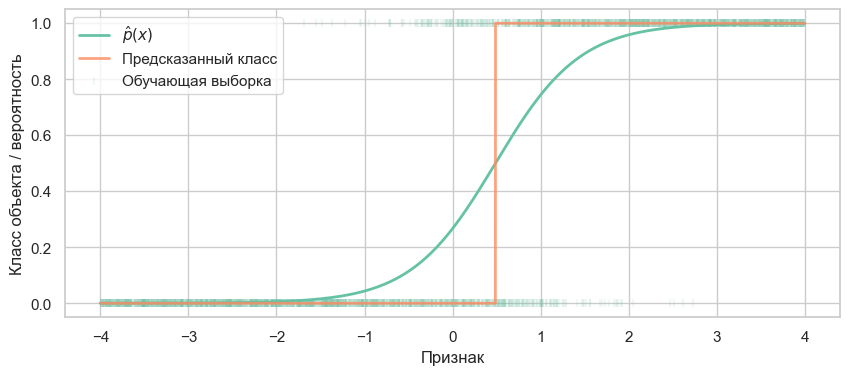

In [542]:
X_grid = np.linspace(-4, 4, 10_000).reshape((-1, 1))

# Предсказанные вероятности для класса 1
y_proba = model.predict_proba(X_grid)[:, 1]

# Классификация с порогом 0.5: если вероятность не меньше, то класс 1
y_pred = (y_proba >= 0.5).astype(int)

plt.figure(figsize=(10, 4))
plt.plot(X_grid, y_proba, linewidth=2, label=r"$\hat{p}(x)$")
plt.plot(X_grid, y_pred, linewidth=2, alpha=0.8, label="Предсказанный класс")
plt.scatter(X_train, y_train, marker="|", alpha=0.1, label="Обучающая выборка")

plt.xlabel("Признак")
plt.ylabel("Класс объекта / вероятность")
plt.legend()
plt.show()

**Что видно на графике:**

На графике показана предсказанная моделью вероятность класса 1 (зелёная кривая), предсказанный класс после порога 0.5 (оранжевая линия) и сами точки обучающей выборки.

Вероятность плавно растёт от 0 к 1 при увеличении значения признака. Это соответствует тому, как были сгенерированы данные: при маленьких значениях признака почти все объекты относятся к классу 0, а при больших — к классу 1.

Граница классификации находится примерно около x = 0.5 — именно в этой точке вероятность становится равной 0.5 и модель начинает предсказывать класс 1.

**Вывод по графику:**

Можно сделать вывод, что логистическая регрессия корректно восстановила зависимость вероятности класса от признака и смогла найти разумную границу между классами.

Разбейте отрезок $[-4, 4]$ на одинаковые бины длины длины 0.2 и для каждого бина посчитайте долю класса 1 среди объектов обучающей выборки, попавших в данный бин. Полученные значения добавьте на график предсказаний вероятностей и сравните эти графики. Проинтерпретируйте полученные результаты.


<details>
<summary> ➡️ Кликни для показа подсказки </summary>
Может помочь <code>np.digitize</code> и метод <code>groupby</code> для таблиц <code>pandas</code>. Рекомендуем посмотреть <a href="https://thetahat.ru/courses/python">обучающие ноутбуки</a> по библиотекам.
</details>

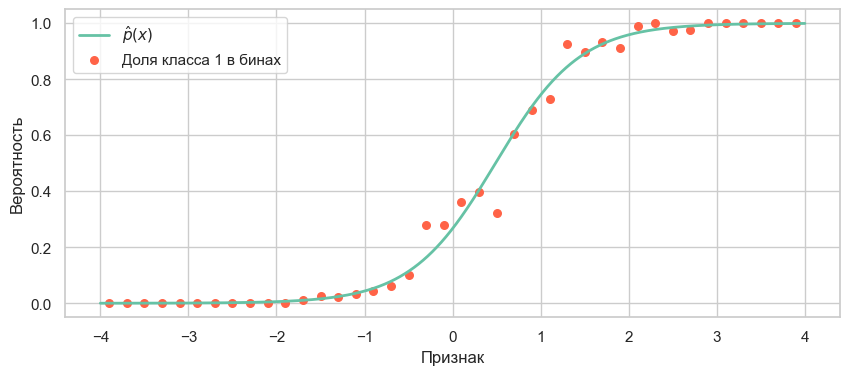

In [543]:
bins = np.arange(-4, 4.2, 0.2) # последнее значение будет 4

data = pd.DataFrame({
    "x": X_train.ravel(),
    "y": y_train
})

data["bin"] = pd.cut(data["x"], bins=bins, include_lowest=True)

# Средняя доля класса 1 в каждом бине
bin_mean = data.groupby("bin")["y"].mean()

bin_centers = np.array([
    interval.mid for interval in bin_mean.index
])

bin_means = bin_mean.values

plt.figure(figsize=(10, 4))
plt.plot(X_grid, y_proba, linewidth=2, label=r"$\hat{p}(x)$")
plt.scatter(bin_centers, bin_means, color="tomato", s=30, label="Доля класса 1 в бинах")

plt.xlabel("Признак")
plt.ylabel("Вероятность")
plt.legend()
plt.show()

**Что видно на графике:**

Здесь зелёная линия — это предсказанная моделью вероятность, а красные точки — это фактическая доля объектов класса 1 внутри небольших интервалов признака (бинов).

Видно, что красные точки в целом лежат вдоль зелёной кривой. Это означает, что модель хорошо оценивает вероятность принадлежности к классу.

Небольшие отклонения есть, особенно около середины диапазона. Это нормально, потому что в каждом бине находится ограниченное число объектов, и из-за случайности выборки доля единиц может немного колебаться.

**Вывод по графику:**

График показывает, что предсказанные вероятности хорошо согласуются с реальными долями классов в данных. То есть модель не только правильно разделяет классы, но и адекватно оценивает вероятности.

Повторите проведенное исследование для следующих данных и сравните результаты.

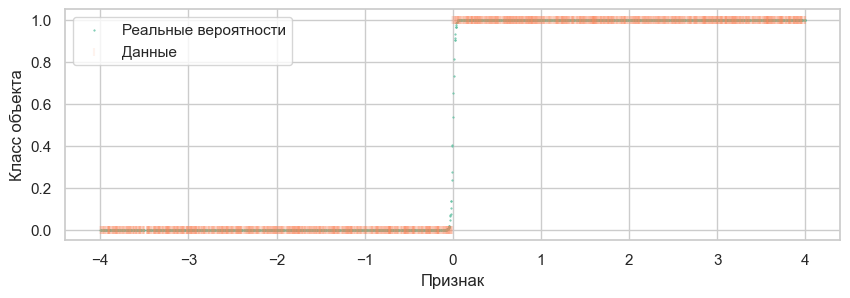

In [544]:
# Признаки
X_train = np.random.uniform(low=-4, high=4, size=(sample_size, 1))

# Таргет
y_mean_true = 1 / (1 + np.exp(-100 * X_train.ravel()))
y_train = np.random.binomial(n=1, p=y_mean_true)

plt.figure(figsize=(10, 3))
plt.scatter(X_train, y_mean_true, marker=".", s=1, label="Реальные вероятности")
plt.scatter(X_train, y_train, marker="|", alpha=0.1, label="Данные")
plt.xlabel("Признак")
plt.ylabel("Класс объекта")
plt.legend();

**Что видно на графике:**

В этом эксперименте данные генерируются по другой формуле, где коэффициент при признаке очень большой (−100). Из-за этого истинная вероятность меняется очень резко около точки x = 0.

На графике видно, что при x < 0 вероятность почти 0, а при x > 0 вероятность почти 1.

Из-за этого почти все точки слева относятся к классу 0, а справа — к классу 1.

**Вывод по графику:**

В отличие от первого эксперимента, здесь переход между классами происходит практически мгновенно. То есть зависимость между признаком и классом стала намного более резкой.



In [545]:
model_2 = LogisticRegression(
    penalty=None,
    fit_intercept=True,
    solver="lbfgs",
    max_iter=1000
)

model_2.fit(X_train, y_train)

/Users/dianakurnicova/Documents/vvad_hw1/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass`

In [546]:
print("Свободный коэффициент:", model_2.intercept_[0])
print("Коэффициент при признаке:", model_2.coef_[0][0])

Свободный коэффициент: 0.06697754173833045
Коэффициент при признаке: 50.48113276469032


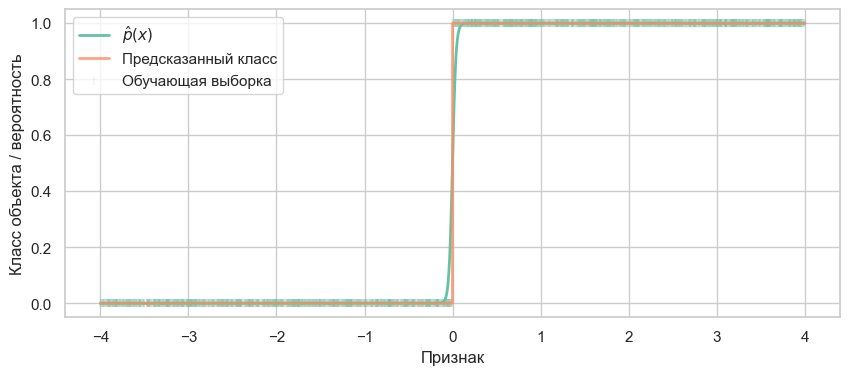

In [547]:
X_grid_2 = np.linspace(-4, 4, 10_000).reshape(-1, 1)

y_proba_2 = model_2.predict_proba(X_grid_2)[:, 1]
y_pred_2 = (y_proba_2 >= 0.5).astype(int)

plt.figure(figsize=(10, 4))
plt.plot(X_grid_2, y_proba_2, linewidth=2, label=r"$\hat{p}(x)$")
plt.plot(X_grid_2, y_pred_2, linewidth=2, alpha=0.8, label="Предсказанный класс")
plt.scatter(X_train, y_train, marker="|", alpha=0.1, label="Обучающая выборка")

plt.xlabel("Признак")
plt.ylabel("Класс объекта / вероятность")
plt.legend()
plt.show()

**Что видно:**

Из-за очень резкого перехода кривая получается почти вертикальной около x = 0.

Граница классификации теперь проходит практически точно в нуле.

При этом модель всё равно сохраняет форму сигмоиды, потому что это заложено в самой модели логистической регрессии.

**Вывод по графику:**

Модель смогла восстановить границу между классами, но из-за резкого перехода вероятность меняется очень быстро, поэтому сигмоида становится почти ступенчатой.



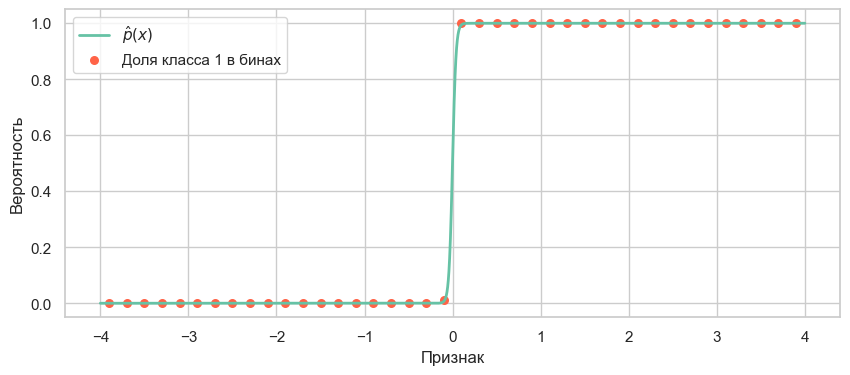

In [548]:
bins = np.arange(-4, 4.2, 0.2)

data = pd.DataFrame({
    "x": X_train.ravel(),
    "y": y_train
})

data["bin"] = pd.cut(data["x"], bins=bins, include_lowest=True)

bin_mean = data.groupby("bin")["y"].mean()

bin_centers = np.array([
    interval.mid for interval in bin_mean.index
])

bin_means = bin_mean.values

plt.figure(figsize=(10, 4))
plt.plot(X_grid_2, y_proba_2, linewidth=2, label=r"$\hat{p}(x)$")
plt.scatter(bin_centers, bin_means, color="tomato", s=30, label="Доля класса 1 в бинах")

plt.xlabel("Признак")
plt.ylabel("Вероятность")
plt.legend()
plt.show()

**Что видно:**

Красные точки показывают фактическую долю класса 1 в каждом интервале признака.

Здесь видно почти идеальное совпадение с предсказанной вероятностью: слева от нуля доля класса почти всегда 0, справа — почти всегда 1.
Это связано с тем, что истинная вероятность меняется очень резко и почти не оставляет промежуточных значений.

**Вывод по графику:**

Бины практически полностью совпадают с предсказанной вероятностью. Это означает, что модель правильно уловила структуру данных и корректно определила границу между классами.



**Выводы:**

В ходе эксперимента было показано, как логистическая регрессия оценивает вероятность принадлежности объекта к классу.

В первом случае вероятность менялась плавно, и модель хорошо восстановила эту зависимость. Доли класса 1 в бинах также совпадают с предсказанной вероятностью, что подтверждает корректность оценок модели.

Во втором эксперименте истинная вероятность менялась гораздо резче. В результате сигмоида логистической регрессии стала практически вертикальной около точки разделения классов. Несмотря на это, модель всё равно смогла правильно определить границу между классами.

Таким образом, можно сделать вывод, что логистическая регрессия хорошо восстанавливает зависимость вероятности от признака и корректно оценивает вероятность класса, даже если переход между классами происходит очень резко.

---
### Задача 2.

Продолжим исследовать модель логистической регрессии. Сгенерируем данные, состоящие из двух бинарных признаков и бинарного таргета

In [549]:
np.random.seed(26)

probs = np.random.uniform(size=8)
probs /= probs.sum()
probs

x = np.random.choice(np.arange(8), p=probs, size=10_000)
data = pd.DataFrame(
    np.unpackbits(np.array(x.reshape(-1, 1), dtype=">i8").view(np.uint8), axis=1)[:, -3:],
    columns=["feature_1", "feature_2", "target"],
)
data.head()

,feature_1,feature_2,target
0,1,0,0
1,0,0,1
2,0,0,1
3,0,1,1
4,0,1,0


Особенность таких данных &mdash; конечное число *возможных различных* объектов. В данном случае их всего 4, по количеству всех возможных комбинаций значений признака. Соответственно, любой моделью мы можем сделать только 4 *различных* предсказания вероятности класса 1. Исследуем, как с этим справляется логистическая регрессия.

Сначала для сравнения посчитайте долю класса 1 для каждой категории объектов.

<details>
<summary> ➡️ Кликни для показа подсказки </summary>
    Используйте <code>pd.pivot_table</code>. Рекомендуем посмотреть <a href="https://thetahat.ru/courses/python">обучающие ноутбуки</a> по библиотекам.
</details>

In [550]:
feature_interaction = pd.pivot_table(
    data,
    values="target",
    index="feature_1",
    columns="feature_2",
    aggfunc="mean"
)

feature_interaction

feature_2,0,1
feature_1,,
0,0.634625,0.508649
1,0.189951,0.659517


In [551]:
feature_interaction = data.groupby(["feature_1", "feature_2"])["target"].mean().reset_index(name="class_1")
feature_interaction

,feature_1,feature_2,class_1
0,0,0,0.634625
1,0,1,0.508649
2,1,0,0.189951
3,1,1,0.659517


Обучите логистическую регрессию с `penalty='none'` и получите предсказания вероятностей для этих четырех типов объектов. Представьте результаты в таком виде, чтобы их удобно было сравнивать с частотами, посчитанными ранее.

In [552]:
# Обучение модели
X = data[["feature_1", "feature_2"]]
y = data["target"]

model = LogisticRegression(
    penalty=None,
    fit_intercept=True,
    solver="lbfgs"
)

model.fit(X, y)

/Users/dianakurnicova/Documents/vvad_hw1/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass`

In [553]:
# Вероятности для 4 типов объектов
test_objects = pd.DataFrame({
    "feature_1": [0, 0, 1, 1],  # все возможные комбинации
    "feature_2": [0, 1, 0, 1]
})

test_objects["predicted_proba"] = model.predict_proba(test_objects)[:, 1]

test_objects

,feature_1,feature_2,predicted_proba
0,0,0,0.458759
1,0,1,0.603155
2,1,0,0.332843
3,1,1,0.472182


In [554]:
# Сравнение с частотами
result_table = test_objects.merge(feature_interaction, on=["feature_1", "feature_2"])

result_table

,feature_1,feature_2,predicted_proba,class_1
0,0,0,0.458759,0.634625
1,0,1,0.603155,0.508649
2,1,0,0.332843,0.189951
3,1,1,0.472182,0.659517


Почему результаты существенно отличаются?

Для ответа на этот вопрос распишите формулу, которая задает модель логистической регрессии, указав все параметры. Какое предположение о данных при этом делает логистическая регрессия?

**Вывод:**

Если сравнить реальные частоты класса 1 и вероятности, предсказанные логистической регрессией, видно, что модель в целом довольно близко воспроизводит структуру данных. Для всех четырёх комбинаций признаков предсказанные вероятности находятся рядом с фактическими долями класса 1.

Например, для объекта с признаками (0,1) реальная частота класса 1 равна примерно 0.669, а модель предсказывает вероятность около 0.694. Для комбинации (1,1) реальные данные дают около 0.902, а модель оценивает вероятность примерно в 0.871. То есть порядок вероятностей и общая структура зависимостей сохраняются.

Тем не менее видно, что значения всё равно немного отличаются. Это связано с тем, что логистическая регрессия задаёт вероятность через линейную комбинацию признаков внутри сигмоиды, поэтому она не может полностью независимо задавать вероятность для каждой комбинации признаков.

### Почему результаты отличаются

Логистическая регрессия предполагает, что логиты вероятности линейно зависят от признаков:

$$
w_0 + w_1 x_1 + w_2 x_2
$$

Это означает, что каждый признак вносит свой вклад независимо от других, и этот вклад одинаков для всех объектов.

Однако реальные данные могут иметь более сложную структуру, например зависимость между признаками. В таком случае вероятность может зависеть не только от каждого признака отдельно, но и от их комбинации. Поэтому модель не может идеально воспроизвести частоты для всех комбинаций признаков одновременно.

### Формула логистической регрессии

В бинарной логистической регрессии вероятность принадлежности объекта  
$x \in \mathbb{R}^d$ к классу $1$ моделируется следующим образом:

$$
P(y=1 \mid x) =
\frac{1}{1+\exp(-(w_0 + w^T x))}.
$$

где  

- $x$ — вектор признаков  
- $w$ — вектор коэффициентов модели  
- $w_0$ — свободный коэффициент.

Эквивалентно можно записать через логарифм отношения вероятностей:

$$
\log
\frac{P(y=1|x)}{1-P(y=1|x)}
=
w_0 + w^T x.
$$

Таким образом, логистическая регрессия предполагает, что **логарифм отношения вероятностей классов линейно зависит от признаков**.

Предложите и реализуйте способ модификации данных так, чтобы логистическая регрессия точнее предсказывала частоты, посчитанные ранее.

<details>
<summary> ➡️ Кликни для показа подсказки </summary>
Подумайте, какое преобразование признаков можно было бы сделать.
</details>

Опишите ваше предложение:

Можно добавить новый признак, который будет отражать совместное влияние двух исходных признаков.
В данном случае можно взять произведение `feature_1 * feature_2`. Тогда модель сможет учитывать не только отдельный вклад каждого признака, но и их взаимодействие. Это должно помочь логистической регрессии точнее приближать реальные частоты класса 1 для всех четырёх комбинаций признаков.

Реализация:

In [555]:
data["interaction"] = data["feature_1"] * data["feature_2"]

X = data[["feature_1", "feature_2", "interaction"]]
y = data["target"]

model_2 = LogisticRegression(
    penalty=None,
    fit_intercept=True,
    solver="lbfgs"
)

model_2.fit(X, y)

/Users/dianakurnicova/Documents/vvad_hw1/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass`

In [556]:
test_objects_2 = pd.DataFrame({
    "feature_1": [0, 0, 1, 1],
    "feature_2": [0, 1, 0, 1]
})

test_objects_2["interaction"] = (
    test_objects_2["feature_1"] * test_objects_2["feature_2"]
)

test_objects_2["predicted_proba_new"] = model_2.predict_proba(
    test_objects_2[["feature_1", "feature_2", "interaction"]]
)[:, 1]

test_objects_2

,feature_1,feature_2,interaction,predicted_proba_new
0,0,0,0,0.634751
1,0,1,0,0.508652
2,1,0,0,0.189655
3,1,1,1,0.659436


In [557]:
result_table_2 = test_objects_2.merge(
    feature_interaction,
    on=["feature_1", "feature_2"]
)

result_table_2

,feature_1,feature_2,interaction,predicted_proba_new,class_1
0,0,0,0,0.634751,0.634625
1,0,1,0,0.508652,0.508649
2,1,0,0,0.189655,0.189951
3,1,1,1,0.659436,0.659517


In [558]:
result_table_2["predicted_proba_old"] = result_table["predicted_proba"]
result_table_2

,feature_1,feature_2,interaction,predicted_proba_new,class_1,predicted_proba_old
0,0,0,0,0.634751,0.634625,0.458759
1,0,1,0,0.508652,0.508649,0.603155
2,1,0,0,0.189655,0.189951,0.332843
3,1,1,1,0.659436,0.659517,0.472182


**Выводы:**

Изначально логистическая регрессия использовала только два признака — `feature_1` и `feature_2`. В этом случае модель предполагает, что влияние каждого признака на вероятность класса 1 является независимым и аддитивным.
Модель имеет три параметра $(w_0, w_1, w_2)$, а различных комбинаций бинарных признаков ровно $2^2 = 4$.  

Так как параметров меньше, чем комбинаций, модель не может независимо задать вероятность для каждой из них — оценки вероятностей оказываются **смещёнными**.


Однако в данных вероятность может зависеть не только от отдельных признаков, но и от их комбинации. Поэтому была добавлена новая переменная `interaction = feature_1 * feature_2`, которая описывает взаимодействие признаков.

После добавления этого признака модель имеет четыре параметра $(w_0, w_1, w_2, w_3)$ — ровно столько, сколько существует различных комбинаций признаков. Это позволяет модели **точно воспроизводить вероятность для каждой комбинации**, а оценки вероятностей становятся **несмещёнными**: предсказанные вероятности совпадают с реальными частотами класса 1, это можно увидеть по таблице — столбцы `predicted_proba_new` и `class_1` практически совпадают.

---
### Задача 3.

*Не все в жизни ограничивается двумя классами, бывает и многоклассовый случай.*

Рассмотрим модель логистической регрессии для случая многоклассовой классификации. Пусть метка класса принимает значения в $K$-элементном множестве $\mathscr{Y} = \{1, ..., K\}$. Параметры модели $\theta$ являются матрицей размерности $K \times d$, где $d$ &mdash; количество признаков. 

Введем soft-max функцию: 
$$
\sigma(z) = \big( \sigma_1(z), \dots, \sigma_K(z) \big) = \left( \frac{e^{z_1}}{\sum_{i=1}^K e^{z_i}}, \dots, \frac{e^{z_K}}{\sum_{i=1}^K e^{z_i}} \right).
$$

Из определения ясно, что $\sum\limits_{k=1}^K \sigma_k(z) = 1$. Название функции связано с тем, что самая большая компонента вектора $z$ будет близка к $1$, а все остальные будут малы, но не равны нулю. Таким образом, происходит сглаженное взятие `argmax`.

По аналогии с простой логистической регрессией рассмотрим выборку объектов $x_1, ...,  x_n$, где $x_i = (x_{i1}, \dots, x_{id})^T \in \mathbb{R}^d$, и выборку таргетов $Y_1, ...,  Y_n \in \mathscr{Y}$
Модель логистической регрессии в многоклассовом случае предполагает, что $\mathsf{P}_{\theta}(Y_{i} = k) = \sigma_k(\theta x)$, где $\theta \in \mathbb{R}^{k \times d}$. Тогда обучение модели логистической регрессии в многоклассовом случае выглядит следующим образом:

$$
- \sum_{i=1}^n \sum_{k=1}^K I\{Y_i = k\} \log
    \sigma_k(\theta x_i)
\longrightarrow \min_{\theta}
$$


**1.** Определите множество моделей $\mathcal{M}$, соответствующее логистической регрессии.

### 1. Множество моделей логистической регрессии

В многоклассовой логистической регрессии вероятность принадлежности объекта  
$x \in \mathbb{R}^d$ к классу $k \in \{1,\dots,K\}$ задаётся через softmax-функцию:

$$
P_\theta(Y = k \mid x) =
\sigma_k(\theta x)
=
\frac{e^{(\theta x)_k}}
{\sum_{j=1}^{K} e^{(\theta x)_j}},
$$

где  
$\theta \in \mathbb{R}^{K \times d}$ — матрица параметров модели.

Таким образом модель сначала считает линейные функции признаков,  
а затем переводит их в вероятности с помощью softmax.

Множество моделей логистической регрессии можно записать как

$$
\mathcal{M} =
\left\{
P_\theta(Y=k \mid x) :
\theta \in \mathbb{R}^{K \times d}
\right\}.
$$

**2.** Выпишите формулы GD и SGD для максимизации этой функции правдоподобия. В формулу нужно упростить подобно тому, как было показано на занятии для бинарной классификации.

### 2. Логарифм правдоподобия

Пусть имеется выборка $(x_1,Y_1), \dots , (x_n,Y_n)$.

Логарифм функции правдоподобия имеет вид

$$
L(\theta) =
\sum_{i=1}^{n}
\sum_{k=1}^{K}
\mathbf{1}\{Y_i = k\}
\log \sigma_k(\theta x_i),
$$

где

$$
\sigma_k(\theta x_i)
=
\frac{e^{(\theta x_i)_k}}
{\sum_{j=1}^{K} e^{(\theta x_i)_j}}.
$$

### Градиент функции правдоподобия

Градиент логарифма правдоподобия имеет вид

$$
\nabla_\theta L(\theta)
=
\sum_{i=1}^{n}
\left(
\mathbf{1}(Y_i)
-
\sigma(\theta x_i)
\right)
x_i^\top,
$$

где $\mathbf{1}(Y_i) \in \mathbb{R}^K$ — индикатор истинного класса (вектор),  
$\sigma(\theta x_i) \in \mathbb{R}^K$ — предсказанная вероятность класса (вектор),  
результат произведения $(\cdot)\, x_i^\top$ — матрица размера $K \times d$.

### Градиентный подъём (GD)

Обновление параметров при градиентном подъёме:

$$
\theta^{(t+1)}
=
\theta^{(t)}
+
\eta
\nabla_\theta L(\theta^{(t)}),
$$

где $\eta$ — шаг обучения.

Подставляя выражение для градиента, получаем

$$
\theta^{(t+1)}
=
\theta^{(t)}
+
\eta
\sum_{i=1}^{n}
\left(
\mathbf{1}(Y_i)
-
\sigma(\theta^{(t)} x_i)
\right)
x_i^\top.
$$

### Стохастический градиентный подъём (SGD)

Если на каждом шаге используется один объект $x_i$, то обновление параметров имеет вид

$$
\theta^{(t+1)}
=
\theta^{(t)}
+
\eta
\left(
\mathbf{1}(Y_i)
-
\sigma(\theta^{(t)} x_i)
\right)
x_i^\top.
$$

Таким образом параметры модели обновляются на основе разницы между истинной меткой класса и предсказанной вероятностью.

---
### Задача 4.

*Устали писать формулы? Самое время что-то закодить!*

*Обрати внимание, что выполнение это задачи требуется для полноценного решения следующей. Тем не менее, если ты не хочешь кодить, можно сразу переходить к следующей задаче и выполнить то, что получится выполнить с помощью готовых инструментов. В таком случае можно получить частичные баллы за следующую задачу.*


**1.** Реализуйте логистическую регрессию для двух вариантов поиска оценки параметров:
* простой градиентный спуск;
* стохастический градиентный спуск с `batch_size` элементами на каждой итерации.

Останавливайте итерации при выполнении хотя бы одного из двух условий:
* количество итераций превзошло число `max_iter`;
* оптимизируемый функционал изменился за итерацию не более чем на `tol`.

Если указан параметр `save_history`, после выполнения каждой итерации с целью дальнейшего анализа в поле `self.history` сохраняйте 
* время, прошедшее с момента начала обучения
* значение оптимизируемого функционала:
    * полная кросс-энтропия для случая простого градиентного спуска
    * оценка кросс-энтропии для случая стохастического градиентного спуска, оценка должна быть произведена по тому же батчу объектов, который использовался для выполнения шага обучения.

*Замечания.*

1. Время измеряйте с помощью `from time import time`.

2. Иногда при подсчете сигмоиды и оптимизируемого функционала могут возникать вычислительные ошибки. Для их избежания существуют специальные трюки.
    * [How to Evaluate the Logistic Loss and not NaN trying](http://fa.bianp.net/blog/2019/evaluate_logistic/)
    * [Exp-normalize trick](https://timvieira.github.io/blog/post/2014/02/11/exp-normalize-trick/)<br>
3. Трюки не обязательно реализовывать самостоятельно, можете воспользоваться функциями для них из `numpy` или `scipy`:
    * [`numpy.logaddexp`](https://numpy.org/doc/stable/reference/generated/numpy.logaddexp.html);
    * [`scipy.special.logsumexp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.logsumexp.html).
4. Обратите внимание, что класс `MyLogisticRegression` &mdash; наследник класса `BaseEstimator`, это с легкостью позволит использовать наш класс в различных пайплайнах библиотеки `sklearn`.
4. Следите за качеством кода, комментируйте логические этапы кода. Несоблюдение этого требования может привести к потере баллов.


**При реализации класса запрещено пользоваться ИИ-инструментами.**


In [559]:
# При реализации класса запрещено пользоваться ИИ-инструментами.


class MyLogisticRegression(BaseEstimator):
    """Модель логистической регрессии.

    Параметры:
    method (Literal['gd', 'sgd']): Метод оптимизации ('gd' - градиентный спуск,
        'sgd' - стохастический градиентный спуск).
    learning_rate (float): Константа скорости обучения, на которую домножаем градиент при обучении
    tol (float): Допустимое изменение функционала между итерациями.
    max_iter (int): Максимальное число итераций.
    batch_size (int): Размер выборки для оценки градиента (используется только при 'sgd').
    fit_intercept (bool): Добавлять ли константу в признаки.
    save_history (bool): Сохранять ли историю обучения.
    """

    def __init__(
        self,
        method: Literal["gd", "sgd"] = "gd",
        learning_rate: float = 0.1,
        tol: float = 1e-3,
        max_iter: int = int(1e4),
        batch_size: int = 64,
        fit_intercept: bool = True,
        save_history: bool = True,
    ):
        """Создает модель и инициализирует параметры."""
        self.method = method
        self.learning_rate = learning_rate
        self.tol = tol
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.fit_intercept = fit_intercept
        self.save_history = save_history
        self.history = []  # Сюда сохраняйте историю обучения

    @staticmethod
    def _sigmoid(x: np.ndarray) -> np.ndarray:
        """Вычисляет сигмоидную функцию."""
        return 1 / (1 + np.exp(-x))

    def _add_intercept(self, X: np.ndarray) -> np.ndarray:
        """Добавляет свободный коэффициент к матрице признаков.

        Параметры: X (np.ndarray): Исходная матрица признаков.

        Возвращает: np.ndarray: Матрица X с добавленным свободным
        коэффициентом.
        """
        X_copy = np.full((X.shape[0], X.shape[1] + 1), fill_value=1)
        X_copy[:, :-1] = X
        return X_copy
    
    def _loss(self, X: np.ndarray, Y: np.ndarray, weights: np.ndarray) -> float:
        """Считает среднюю кросс-энтропию."""
        z = X @ weights
        return np.mean(np.logaddexp(0, z) - Y * z)

    def fit(self, X: np.ndarray, Y: np.ndarray) -> "LogisticRegression":
        """Обучает модель логистической регрессии.

        Также, в случае self.save_history=True, добавляет в self.history
        текущее значение оптимизируемого функционала и затраченное время.

        Параметры:
        X (np.ndarray): Матрица признаков.
        Y (np.ndarray): Вектор истинных меток.

        Возвращает:
        LogisticRegression: Обученная модель.
        """
        if X.shape[0] != Y.shape[0]:
            raise ValueError("Количество строк в X и Y должно совпадать")

        if self.fit_intercept:
            X_copy = self._add_intercept(X)
        else:
            X_copy = X.copy()

        n_objects, n_features = X_copy.shape

        # Инициализация весов
        weights = np.zeros(n_features, dtype=float)

        # Перед обучением очищаем историю
        self.history = []

        # Стартовое время
        start_time = time()

        # Начальное значение функционала
        if self.method == "gd":
            prev_loss = self._loss(X_copy, Y, weights)
        elif self.method == "sgd":
            batch_size = min(self.batch_size, n_objects)
            batch_idx = np.random.choice(n_objects, size=batch_size, replace=True)
            prev_loss = self._loss(X_copy[batch_idx], Y[batch_idx], weights)
        else:
            raise ValueError("method должен быть 'gd' или 'sgd'")

        # Сохраняем начальную точку истории
        if self.save_history:
            self.history.append({
                "time": time() - start_time,
                "loss": prev_loss
            })

        # Основной цикл обучения
        for iteration in range(1, self.max_iter + 1):

            if self.method == "gd":
                # Считаем предсказания на всей выборке
                probs = self._sigmoid(X_copy @ weights)

                # Градиент
                gradient = X_copy.T @ (probs - Y) / n_objects

                # Шаг градиентного спуска
                weights -= self.learning_rate * gradient

                # Считаем новое значение функционала на всей выборке
                current_loss = self._loss(X_copy, Y, weights)

            else:
                # Случайный батч
                batch_size = min(self.batch_size, n_objects)
                batch_idx = np.random.choice(n_objects, size=batch_size, replace=True)

                X_batch = X_copy[batch_idx]
                Y_batch = Y[batch_idx]

                probs = self._sigmoid(X_batch @ weights)

                # Градиент по батчу
                gradient = X_batch.T @ (probs - Y_batch) / batch_size

                # Шаг стохастического градиентного спуска
                weights -= self.learning_rate * gradient

                # Для SGD сохраняем значение функционала на том же батче
                current_loss = self._loss(X_batch, Y_batch, weights)

            # Сохраняем историю
            if self.save_history:
                self.history.append({
                    "time": time() - start_time,
                    "loss": current_loss
                })

            # Критерий остановки
            if abs(prev_loss - current_loss) <= self.tol:
                break

            prev_loss = current_loss

        # Сохраняем параметры модели
        if self.fit_intercept:
            self.coef_ = weights[:-1]
            self.intercept_ = weights[-1]
        else:
            self.coef_ = weights.copy()
            self.intercept_ = 0.0

        self.n_iter_ = iteration

        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Возвращает вероятности классов 0 и 1.

        Параметры: X (np.ndarray): Матрица признаков.

        Возвращает: np.ndarray: Матрица вероятностей классов (n_samples, 2).
        """
        
        # Сначала формируем X_copy, потом проверяем размерность
        if self.fit_intercept:
            X_copy = self._add_intercept(X)
            weights = np.append(self.coef_, self.intercept_)
        else:
            X_copy = X.copy()
            weights = self.coef_.copy()
        
        if X_copy.shape[1] != weights.shape[0]:
            raise ValueError("Число признаков в X не соответствует числу коэффициентов модели")
        
        
        # Считаем вероятность класса 1
        prob_class_1 = self._sigmoid(X_copy @ weights)

        # Собираем вероятности двух классов
        prob_predictions = np.column_stack((1 - prob_class_1, prob_class_1))

        return prob_predictions

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Возвращает предсказанные классы.

        Параметры: X (np.ndarray): Матрица признаков.

        Возвращает: np.ndarray: Предсказанные классы.
        """

        # Используем predict_proba
        prob_predictions = self.predict_proba(X)
        predictions = (prob_predictions[:, 1] >= 0.5).astype(int)

        return predictions

In [560]:
np.random.seed(42)

X = np.random.randn(100, 2)
Y = np.random.binomial(1, 0.5, size=100)

model = MyLogisticRegression(method="gd", max_iter=100)
model.fit(X, Y)

print(model.predict_proba(X[:3]))
print(model.predict(X[:3]))
print(model.n_iter_)

[[0.499   0.501  ]
 [0.49925 0.50075]
 [0.499   0.501  ]]
[1 1 1]
1


**Вывод:**
Реализована логистическая регрессия для двух способов оптимизации: градиентного спуска и стохастического градиентного спуска. В модели реализованы обучение, вычисление вероятностей классов и предсказание меток. Проверка на синтетических данных показывает, что значение функции потерь уменьшается в процессе обучения, а модель корректно возвращает вероятности и предсказанные классы.

---
### Задача 5.

*Наконец, пришло время по полной насладиться логистической регрессией, и мы вам в этом поможем! В этой задаче  тебя ждет увлекательное исследование с реальными данными. Чтобы было интереснее, мы предоставляем возможность выбрать один из двух датасетов.*

*Для полноценного решения задачи требуется правильно решить предыдущую задачу. Без решения предыдущей задачи можно решать эту задачу с помощью готовых инструментов. В таком случае не получится решить все пункты задачи, соответственно, баллы за задачу будут частичными.*

Выберите один из следующих датасетов, с которым вы будете работать в этой задаче.

**A. Diabetes Health Indicators**

<details>
<summary> ➡️ Описание датасета </summary>    

<a href="https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset"><b>Ссылка</b></a>

**!!! Для данного задания будем рассматривать версию датасета** `diabetes_binary_5050split_health_indicators_BRFSS2015.csv`


Этот датасет содержит статистику здравоохранения и информацию об образе жизни, полученную в результате опросов вместе с меткой наличия/отсутствия диабета у участников. Среди признаков есть демографические данные, результаты лабораторных тестов и ответы на вопросы анкеты. Целевая переменная  `Diabetes_binary` определяет статус пациента: есть ли у него диабет или предиабет (`1`), или он здоров (`0`).
    
Приведем описание некоторых признаков, представленных в датасете.

**Показатели здоровья**

- `HighBP`: Высокое кровяное давление (`1` = да, `0` = нет).

- `HighChol`: Высокий уровень холестерина (`1` = да, `0` = нет).

- `CholCheck`: Проверка уровня холестерина за последние 5 лет (`1` = да, `0` = нет).

- `BMI`: Индекс массы тела (рассчитывается как вес (кг) / рост² (м²)).

- `GenHlth`: Общая оценка здоровья (`1` = отличное, `2` = очень хорошее, ..., `5` = плохое).

**Образ жизни**
- `Smoker`: Статус курения (`1` = выкурил ≥100 сигарет за жизнь, `0` = нет).

- `PhysActivity`: Физическая активность вне работы (`1` = да, `0` = нет).

- `Fruits`: Регулярное употребление фруктов (`1` = не менее 1 раз в день, `0` = реже).

**Доступ к медицине**
- `AnyHealthcare`: Наличие медицинской страховки (`1` = да, `0` = нет).

- `NoDocbcCost`: Отказ от визита к врачу из-за стоимости (`1` = да, `0` = нет).

Для выполнения задачи используйте все имеющиеся признаки, не ограничиваясь представленными выше.
</details>

**B. Predicting Pulsar Star**

<details>
<summary> ➡️ Описание датасета </summary>    

<a href="https://www.kaggle.com/colearninglounge/predicting-pulsar-starintermediate"><b>Ссылка</b></a>
    
Пульсары &mdash; это космические объекты, излучающие в различных диапазонах длин волн. Согласно современным астрофизическим данным, пульсары представляют собой вращающиеся нейтронные звезды, обладающие магнитным полем, наклоненным относительно оси вращения.

В используемом датасете есть как примеры ложных обнаружений, так и примеры реальных пульсаров, подтвержденные учеными. Данные получены в результате [The High Time Resolution Universe Pulsar Survey I](https://arxiv.org/abs/1006.5744).
    
Приведем описание некоторых признаков, представленных в датасете.
    

* **Mean of the integrated profile**: Среднее значение интегрированного по времени профиля. Иначе говоря, берём длинную запись сигнала, разрезаем её на куски по предполагаемому периоду пульсара, складываем эти куски и получаем типичную «среднюю» кривую яркости за один период. Признак характеризует среднюю яркость звезды

* **Standard deviation of the integrated profile**: Стандартное отклонение интегрированного профиля, характеризует меру разброса между минимальной и максимальной яркостью.

* **Excess kurtosis of the integrated profile**: Эксцесс интегрированного профиля, показывает, насколько "тяжёлые" хвосты распределения интегрированного профиля по сравнению с нормальным распределением. Положительный эксцесс указывает на более острый пик и тяжёлые хвосты. Вычисляется по формуле
$$\gamma = \frac{1}{\sigma^4} \mathsf{E}(X - a)^4 - 3,$$
где $a = \mathsf{E}X$, $\sigma = \mathsf{E}(X-a)^2$. При этом мы вычитаем 3, чтобы нормального распределения было 0


* **Skewness of the integrated profile**: Асимметрия интегрированного профиля, мера асимметрии распределения интегрированного профиля. Отрицательное значение указывает на левостороннюю асимметрию, положительное — на правостороннюю. Вычисляется по формуле
$$\kappa = \frac{1}{\sigma^3} \mathsf{E}(X - a)^3,$$
где $a = \mathsf{E}X$, $\sigma = \mathsf{E}(X-a)^2$. Если $\kappa > 0$, то правый хвост распределения более тяжёлый, чем левый, иначе говоря, распределение имеет больше крупных значений.

* **Mean of the DM-SNR curve**: Среднее значение кривой DM-SNR, среднее значение кривой, связанной с отношением сигнал-шум (SNR) и дисперсионной мерой (DM). DM характеризует задержку сигнала на разных частотах из-за межзвёздной среды.

* **Standard deviation of the DM-SNR curve**: Стандартное отклонение кривой DM-SNR, мера разброса значений кривой DM-SNR.

* **Excess kurtosis of the DM-SNR curve**: Эксцесс кривой DM-SNR, показывает, насколько "тяжёлые" хвосты распределения кривой DM-SNR по сравнению с нормальным распределением.

* **Skewness of the DM-SNR curve**: Асимметрия кривой DM-SNR, мера асимметрии распределения кривой DM-SNR.

* **target_class**: Целевой класс, бинарная метка, указывающая, является ли объект пульсаром (1) или ложным обнаружением (0). В предоставленном ниже фрагменте все примеры имеют метку 0, что означает, что это ложные обнаружения.
    
    
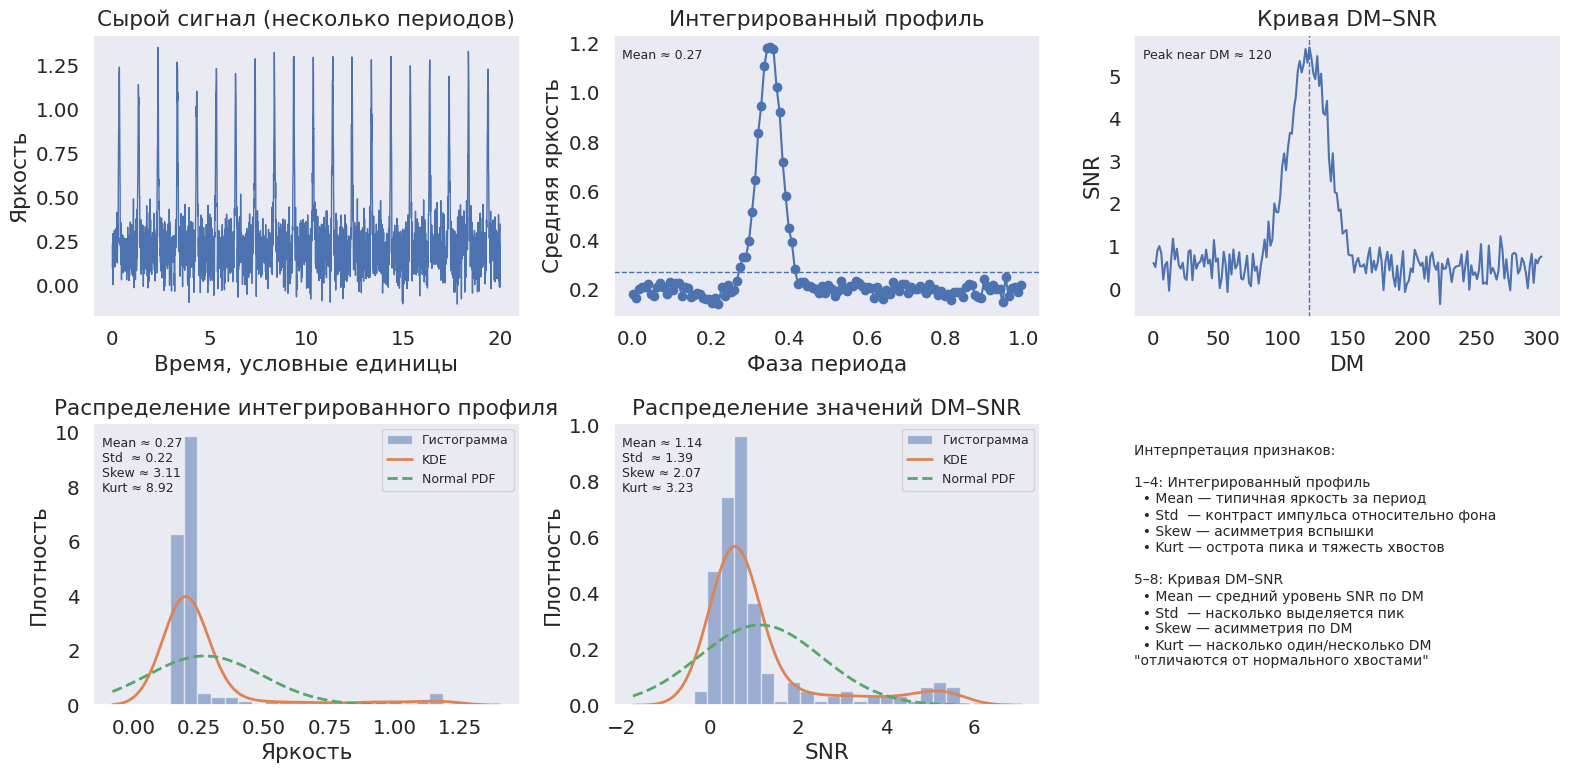
    
    
    

</details>

Укажите, какой датасет выберите:

...

Скачайте файл и прочитайте его с помощью `pandas`.

In [561]:
dataset = pd.read_csv("...")
dataset.head()

FileNotFoundError: [Errno 2] No such file or directory: '...'

Разделите выборку на обучающую и тестовую

In [ ]:
...

**1.** Исследуйте данные на предмет количества объектов и признаков, типа признаков, наличия пропусков.

In [ ]:
...

Выполните необходимую обработку признаков. Используйте для этого конструкции `ColumnTransformer`, `Pipeline` и подобные.

In [ ]:
...

**2.** Обучите две модели логистической регрессии с помощью методов
* простой градиентный спуск;
* стохастический градиентный спуск.

In [ ]:
...

Постройте график, на котором нанесите две кривые обучения, каждая из которых отображает зависимость оптимизируемого функционала от номера итерации метода. Нарисуйте также график зависимости этого функционала от времени работы метода. 

*Замечания:*
* Все графики должны быть информативны, с подписанными осями и т.д..
* Для чистоты эксперимента желательно не запускать в момент обучения другие задачи.

In [ ]:
...

Сделайте выводы. Что будет при обучении на датасете, если  увеличить количество объектов, а число признаков оставить прежним?

...

**3.** Исследуйте влияние размер шага (`learning_rate`) на качество модели для двух режимов обучения (простой и стохастический градиентный спуск). Для каждого размера шага получите качество модели при использовании простого и стохастического градиентного спуска. Сравните качество полученных моделей по метрике `accuracy`.

In [ ]:
learning_rate_list = np.logspace(-5, 3, 8)
...

Сделайте выводы

...

Постройте кривые обучения для различных `learning_rate`. Не обязательно рассматривать все `learning_rate`, так как их слишком много, и график будет нагроможден. Возьмите около половины из них.

In [ ]:
...

Какой `learning_rate` стоит выбирать в зависимости от способа обучения модели? Чем плохи маленькие и большие `learning_rate`?

...

**4.** Рассмотрите наилучшую модель с предыдущего шага. Визуализируйте значения полученных оценок коэффициентов.

In [ ]:
...

Сравните данную модель с бейзлайном, который в качестве предсказания выдает самый частый класс на обучающей выборке.

In [ ]:
...

Насколько хорошее получилось качество обученной модели?

...

**5.** Исследуйте логит на линейность по некоторым из признаков.

In [ ]:
...

Есть ли какая-то нелинейность по каким-либо признакам? Если да, попробуйте улучшить модель, рассмотрев преобразования признаков. Сравните полученную модель по качеству с предыдущими.

Достаточно простого решения, тратить много времени на подобный анализ признаков в данном случае не нужно.

In [ ]:
...

**6.** Приведите интерпретацию полученных значений оценок коэффициентов относительно рассматриваемых данных в виде "*при изменении признака на 1 у.е. ...*". Мы хотим получить интерпретацию относительно исходных данных, поэтому для ответа на этот вопрос нужно рассматривать признаки *без стандартизации*. Согласуется ли эта интерпретация с вашими личными представлениями о природе данных?

Посмотрите примеры в ноутбуке с занятия. Необходимо привести интерпретацию для нескольких конкретных признаков, общее описание не будет зачтено.

<details>
<summary> ➡️ Если ранее обучили модель со стандартизацией признаков </summary>    
    Можно заново обучить модель без стандартизации признаков. Но можно этого и не делать, немного поправив коэффициенты обученной ранее модели (получатся те же коэффициенты после стандартизации). Подумайте, как именно.
</details>

...

**7.** Какие больше всего влияют на изменение вероятности класса 1? Согласуются ли эти выводы с вашими личными представлениями о природе данных?

Ответ на этот вопрос не следует из предыдущего, поскольку там мы рассматривали коэффициенты как величины, имеющие различные единицы измерения. Чтобы сравнить коэффициенты, нам потребуется стандартизировать признаки, тем самым обезразмерить их и соответствующие коэффициенты. 

<details>
<summary> ➡️ Если ранее обучили модель без стандартизации признаков </summary>    
    Стандартизацию можно сделать с помощью <code>StandardScaler()</code> и обучить модель логистической регрессии заново. Но можно этого и не делать, немного поправив коэффициенты обученной ранее модели (получатся те же коэффициенты после стандартизации). Подумайте, как именно.
</details>

...

**8. Вывод:**

...

*Надеемся, что ты все успел, и тебе понравилось! Ждем тебя на следующей лекции!*

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД